# Stage 9: Asset allocation

So far every portfolio held only Indian stocks and T-bills. Most of an investor's long-run risk and
return comes from a bigger decision: **how much to hold in each asset class**.

This stage adds gold and government bonds, then compares three approaches:

- **Strategic allocation:** fixed long-term weights, rebalanced regularly.
- **Risk parity:** weights set so each asset contributes equally to risk.
- **Black-Litterman:** start from a neutral allocation, then adjust for specific views. This avoids
  relying on the historical means that have been unreliable in every stage so far.

It uses **estimation months only**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import allocation as al
from pmo import backtest, models, stats
from pmo import frontier as fr
from pmo import investor as inv
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import asset_class_prices, load
from pmo.plotting import FIGURES, MUTED, PALETTE, SERIES_1, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
market = config.market_proxy
HAIRCUT = config.survivorship_haircut

prices = asset_class_prices()
monthly = ret.monthly_returns(ret.complete_month_prices(prices.ffill(), data.prices.index.max()))
monthly = monthly.reindex(data.returns.index)
rf = data.risk_free["rf"]
extra = monthly.sub(rf, axis=0)
extra["Equity"] = data.excess[market]
all_excess = ret.select_period(extra, data.periods, "estimation")
ASSETS = ["Equity", "Gold", "Bonds"]
assets = all_excess[ASSETS]
RISK_FREE = rf.loc[assets.index].mean() * 12
print(f"{len(assets)} months; equity sleeve is {market}")

153 months; equity sleeve is NIFTYBEES


## 1. The data

| Asset class | Source | Limitation |
|---|---|---|
| **Equity** | NIFTYBEES | Same proxy as earlier stages, and free of stock survivorship |
| **Gold** | GOLDBEES ETF | Same December 2019 misprint as NIFTYBEES, removed |
| **Bonds** | SBI 10 Year Constant Maturity Gilt Fund | Net of fees, but see below |
| **Cash** | 91-day T-bill | Checked against a liquid fund below |

Bond ETFs started too late, so a long-running gilt fund stands in. Two checks follow: is the fund a
fair stand-in for long gilts, and can a real investor earn the T-bill rate? The liquid fund's NAV also
had a one-day jump of about 100 times from a change in unit size, which is removed.

In [2]:
total = assets.add(rf.loc[assets.index], axis=0)
summary = stats.asset_summary(total, rf.loc[assets.index])
liquid = all_excess["Liquid fund"]
print(f"Liquid fund minus T-bill: {liquid.mean() * 12:.2%} a year, "
      f"tracking volatility {liquid.std() * np.sqrt(12):.2%}, "
      f"correlation {(liquid + rf.loc[liquid.index]).corr(rf.loc[liquid.index]):.2f}")

summary[["mean", "cagr", "volatility", "sharpe", "max_drawdown", "skew"]].round(3)

Liquid fund minus T-bill: 0.46% a year, tracking volatility 0.18%, correlation 0.96


,mean,cagr,volatility,sharpe,max_drawdown,skew
Equity,0.119,0.110,0.164,0.335,-0.288,-0.599
Gold,0.087,0.080,0.142,0.163,-0.244,0.527
Bonds,0.082,0.085,0.027,0.684,-0.036,-0.128


**Liquid funds track T-bills closely**, so cash in this project is something a real investor can
hold. The Stage 5 question about a cash-like asset is answered, and LIQUIDBEES isn't needed.

**The bond figures need care.** A 10-year gilt fund should be more volatile than this. The fund's
volatility looks more like a shorter-duration fund's over much of the period, and it is a survivor
too: a similar scheme's data stops in 2018. So its Sharpe ratio overstates what bonds offer, and optimizers
that take this figure at face value will overweight it.

## 2. Why diversify across asset classes?

In [3]:
worst = assets["Equity"].nsmallest(15).index
stress = pd.DataFrame({
    "Worst 15 equity months": total.loc[worst].mean(),
    "March 2020": total.loc["2020-03-31"],
    "August 2011": total.loc["2011-08-31"],
    "August 2013": total.loc["2013-08-31"],
    "September 2018": total.loc["2018-09-30"],
}).T * 100
print("Correlations of monthly returns")
print(assets.corr().round(2))
print()
stress.round(1)

Correlations of monthly returns
        Equity  Gold  Bonds
Equity    1.00 -0.17   0.06
Gold     -0.17  1.00   0.02
Bonds     0.06  0.02   1.00



,Equity,Gold,Bonds
Worst 15 equity months,-7.2,4.0,1.1
March 2020,-22.9,2.2,0.8
August 2011,-9.7,16.1,0.8
August 2013,-5.2,8.9,-0.3
September 2018,-6.4,-0.1,0.2


Gold is the standout. Its correlation with equity is slightly negative, and it rose on average in
the worst equity months. That isn't guaranteed: September 2018 shows a month where it didn't help.

### Where the risk really sits

A 60/20/20 portfolio looks balanced by capital, but not by risk.

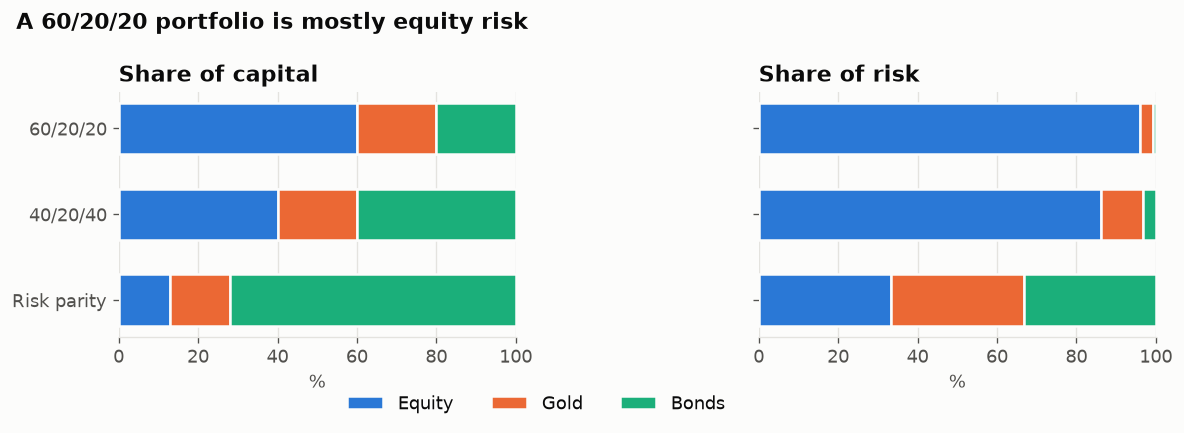

,60/20/20,40/20/40,Risk parity
Equity,0.960,0.862,0.333
Gold,0.034,0.105,0.333
Bonds,0.006,0.033,0.333


In [4]:
cov = assets.cov() * 12
policies = {"60/20/20": pd.Series({"Equity": 0.6, "Gold": 0.2, "Bonds": 0.2}),
            "40/20/40": pd.Series({"Equity": 0.4, "Gold": 0.2, "Bonds": 0.4})}
inverse = al.inverse_volatility(cov)
parity = al.risk_parity(cov)
policies["Risk parity"] = parity

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
labels = list(policies)
for ax, title, shares in [
        (axes[0], "Share of capital", [policies[name][ASSETS] for name in labels]),
        (axes[1], "Share of risk", [al.risk_contributions(policies[name], cov)[ASSETS] for name in labels])]:
    left = np.zeros(len(labels))
    for position, asset in enumerate(ASSETS):
        values = np.array([share[asset] * 100 for share in shares])
        ax.barh(labels, values, left=left, height=0.6, color=PALETTE[position], edgecolor=SURFACE,
                linewidth=1.5, label=asset)
        left += values
    ax.set_title(title)
    ax.set_xlim(0, 100)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.invert_yaxis() if ax is axes[0] else None
axes[1].set_xlabel("%")
axes[0].set_xlabel("%")
axes[0].legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(1.05, -0.17))
fig.suptitle("A 60/20/20 portfolio is mostly equity risk", x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "09_risk_budget.png")
plt.show()
pd.DataFrame({name: al.risk_contributions(weights, cov) for name, weights in policies.items()}).round(3)

## 3. Black-Litterman

Optimizing on historical means is unreliable, as every earlier stage showed. The Black-Litterman
approach reverses the problem:

1. Assume a neutral allocation is correct. Here that's **60/20/20**, an assumption, because India has
   no clean measure of the total market across asset classes.
2. Work out what expected returns would make it optimal: π = δ Σ w. δ comes from the long-run equity
   premium.
3. Blend in any views, weighted by confidence.

Two views are used, both illustrative and well below the historical averages: bonds earn 1.5 points
more than T-bills, and gold earns 1.5 points more than T-bills.

In [5]:
PRIOR = pd.Series({"Equity": 0.6, "Gold": 0.2, "Bonds": 0.2})
VIEWS = pd.DataFrame([[0, 0, 1], [0, 1, 0]], columns=ASSETS, dtype=float)
VIEW_RETURNS = pd.Series([0.015, 0.015])
GOLD_LIMIT = pd.Series({"Equity": 1.0, "Gold": 0.25, "Bonds": 1.0})


def premium(frame):
    return data.factors_long.loc[:frame.index.max(), "MKT_RF"].mean() * 12


def posterior(frame, views=True):
    annual = frame[ASSETS].cov() * 12
    delta = premium(frame) / annual.loc["Equity", "Equity"]
    if views:
        return al.black_litterman(PRIOR, annual, delta, VIEWS, VIEW_RETURNS), annual
    return al.black_litterman(PRIOR, annual, delta), annual


implied, annual = posterior(assets, views=False)
blended, _ = posterior(assets)
rows = {"Historical excess return": assets.mean() * 12, "Implied by 60/20/20": implied,
        "With the two views": blended}
print(f"Risk aversion implied by the prior: {premium(assets) / annual.loc['Equity', 'Equity']:.1f}")
returns_table = pd.DataFrame(rows).T
returns_table.round(3)

Risk aversion implied by the prior: 3.1


,Equity,Gold,Bonds
Historical excess return,0.055,0.023,0.018
Implied by 60/20/20,0.048,0.005,0.001
With the two views,0.050,0.010,0.008


In [6]:
rows = {}
for profile in inv.PROFILES:
    mix = al.best_mix(blended, annual, profile.risk_aversion, GOLD_LIMIT)
    rows[profile.name] = {**mix.to_dict(), "Cash": 1 - mix.sum()}
for name, weights in [("Optimizer on historical means, A = 4",
                       al.best_mix(assets.mean() * 12, annual, 4.0, GOLD_LIMIT))]:
    rows[name] = {**weights.to_dict(), "Cash": 1 - weights.sum()}
pd.DataFrame(rows).T.round(3)

,Equity,Gold,Bonds,Cash
Cautious,0.220,0.084,0.697,0.0
Balanced,0.418,0.133,0.449,0.0
Growth,0.795,0.205,0.000,0.0
"Optimizer on historical means, A = 4",0.375,0.155,0.469,0.0


## 4. Which allocation worked?

The walk-forward test now covers asset classes, refitting yearly and with no costs. As in every
stage so far, weights are reset to target each month, which is a simplification that Stage 10 removes.
Fixed-weight policies need no estimates. The holdout remains untouched.

In [7]:
def fixed(**weights):
    return lambda train: pd.Series(weights, dtype=float)


strategies = {
    "100% equity": fixed(Equity=1.0),
    "80/10/10": fixed(Equity=0.8, Gold=0.1, Bonds=0.1),
    "60/40 equity and bonds": fixed(Equity=0.6, Bonds=0.4),
    "60/20/20": fixed(Equity=0.6, Gold=0.2, Bonds=0.2),
    "40/20/40": fixed(Equity=0.4, Gold=0.2, Bonds=0.4),
    "25/15/60": fixed(Equity=0.25, Gold=0.15, Bonds=0.6),
    "Risk parity": lambda train: al.risk_parity(train[ASSETS].cov()),
    "Black-Litterman, A = 4": lambda train: al.best_mix(*posterior(train), 4.0, GOLD_LIMIT),
}
columns = ["excess_return", "volatility", "sharpe", "max_drawdown", "turnover"]
results = {w: backtest.run(assets, strategies, window=w, step=12) for w in [60, 36]}
pd.concat({f"{w}-month window": backtest.scorecard(r)[columns] for w, r in results.items()}).round(3)

excess_return  volatility  sharpe  \
60-month window 100% equity                     0.093       0.169   0.552   
                80/10/10                        0.082       0.134   0.610   
                60/40 equity and bonds          0.064       0.102   0.632   
                60/20/20                        0.071       0.102   0.693   
                40/20/40                        0.057       0.072   0.791   
                25/15/60                        0.044       0.050   0.893   
                Risk parity                     0.036       0.040   0.898   
                Black-Litterman, A = 4          0.053       0.078   0.677   
36-month window 100% equity                     0.081       0.161   0.505   
                80/10/10                        0.069       0.128   0.538   
                60/40 equity and bonds          0.058       0.098   0.592   
                60/20/20                        0.056       0.097   0.579   
                40/20/40                        0.045       0.068   0.653   
                25/15/60                        0.036       0.047   0.765   
                Risk parity                     0.031       0.040   0.782   
                Black-Litterman, A = 4          0.035       0.082   0.429   

                                        max_drawdown  turnover  
60-month window 100% equity                   -0.313     0.000  
                80/10/10                      -0.232     0.000  
                60/40 equity and bonds        -0.176     0.000  
                60/20/20                      -0.164     0.000  
                40/20/40                      -0.099     0.000  
                25/15/60                      -0.055     0.000  
                Risk parity                   -0.045     0.037  
                Black-Litterman, A = 4        -0.114     0.099  
36-month window 100% equity                   -0.313     0.000  
                80/10/10                      -0.232     0.000  
                60/40 equity and bonds        -0.176     0.000  
                60/20/20                      -0.174     0.000  
                40/20/40                      -0.119     0.000  
                25/15/60                      -0.074     0.000  
                Risk parity                   -0.046     0.045  
                Black-Litterman, A = 4        -0.212     0.171

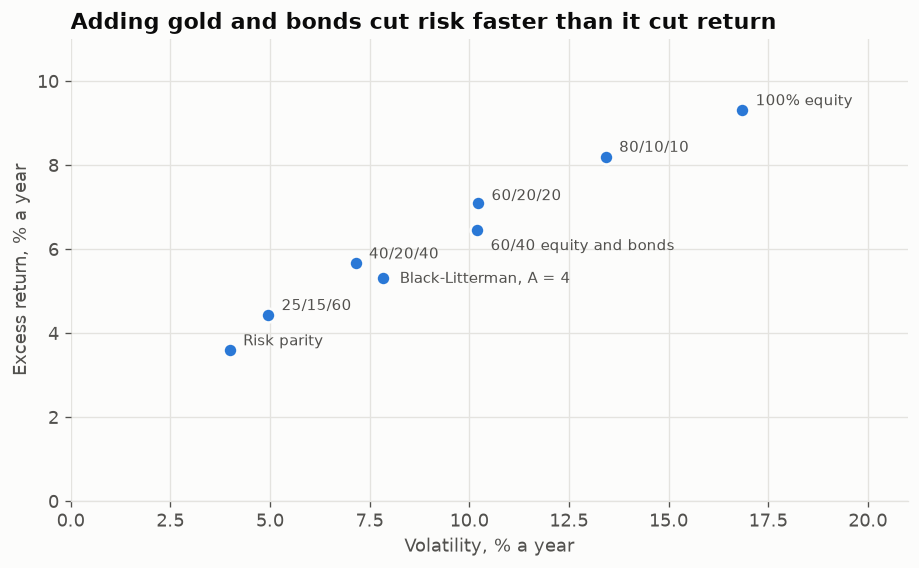

In [8]:
card = backtest.scorecard(results[60])
fig, ax = plt.subplots(figsize=(9, 5))
ax.grid(axis="x")
ax.scatter(card["volatility"] * 100, card["excess_return"] * 100, s=70, color=SERIES_1,
           edgecolor=SURFACE, linewidth=1.5, zorder=3)
offsets = {"60/40 equity and bonds": (8, -12), "60/20/20": (8, 2), "Black-Litterman, A = 4": (10, -3)}
for name, row in card.iterrows():
    dx, dy = offsets.get(name, (8, 3))
    ax.annotate(name, (row["volatility"] * 100, row["excess_return"] * 100), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=MUTED)
ax.set_xlim(0, 21)
ax.set_ylim(0, 11)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Excess return, % a year")
ax.set_title("Adding gold and bonds cut risk faster than it cut return")
fig.savefig(FIGURES / "09_allocations.png")
plt.show()

Sharpe ratio isn't the whole story here. Risk parity scores well partly through its large position
in the bond fund, whose risk looks understated, and an unlevered investor gets a low absolute return.

## 5. Allocations for each investor type

Investors care about their utility, so this measures the **realized certainty-equivalent excess
return** of each fixed policy for each type. The equity sleeve is tested two ways: the Nifty, and the
capped stock fund from earlier stages less the 3-point survivorship haircut. Higher is better.

In [9]:
def fund_strategy(train):
    rate = rf.loc[train.index].mean() * 12
    mean, stock_cov = fr.annualize(*models.practical_inputs(
        train[stocks], train[market],
        data.factors_long.loc[:train.index.max(), "MKT_RF"].mean()), rate)
    return fr.solve_max_sharpe(mean - HAIRCUT, stock_cov, rate, fr.Constraints(upper=0.10))


stock_excess = ret.select_period(data.excess, data.periods, "estimation")
fund = backtest.run(stock_excess, {"Fund": fund_strategy}, window=60, step=12).returns["Fund"]
fund_net = fund - HAIRCUT / 12

policy_set = {"100/0/0": (1.0, 0, 0), "80/10/10": (0.8, 0.1, 0.1), "60/20/20": (0.6, 0.2, 0.2),
              "40/20/40": (0.4, 0.2, 0.4), "25/15/60": (0.25, 0.15, 0.6)}
tested = assets.loc[fund.index]
rows = {}
for sleeve, equity in [("Nifty", tested["Equity"]), ("Fund less haircut", fund_net)]:
    for name, (e, g, b) in policy_set.items():
        series = e * equity + g * tested["Gold"] + b * tested["Bonds"]
        mean_excess, sd = series.mean() * 12, series.std() * np.sqrt(12)
        row = {"excess_return": mean_excess, "volatility": sd,
               "max_drawdown": stats.max_drawdown(series)}
        for profile in inv.PROFILES:
            row[profile.name] = float(inv.utility(mean_excess, sd, profile.risk_aversion))
        rows[sleeve, name] = row
utility_table = pd.DataFrame(rows).T
utility_table.round(3)

excess_return  volatility  max_drawdown  Cautious  \
Nifty             100/0/0           0.093       0.169        -0.313    -0.021   
                  80/10/10          0.082       0.134        -0.232     0.010   
                  60/20/20          0.071       0.102        -0.164     0.029   
                  40/20/40          0.057       0.072        -0.099     0.036   
                  25/15/60          0.044       0.050        -0.055     0.034   
Fund less haircut 100/0/0           0.115       0.164        -0.206     0.007   
                  80/10/10          0.100       0.132        -0.155     0.030   
                  60/20/20          0.084       0.102        -0.104     0.043   
                  40/20/40          0.065       0.072        -0.076     0.045   
                  25/15/60          0.050       0.051        -0.063     0.039   

                            Balanced  Growth  
Nifty             100/0/0      0.036   0.065  
                  80/10/10     0.046   0.064  
                  60/20/20     0.050   0.060  
                  40/20/40     0.046   0.051  
                  25/15/60     0.039   0.042  
Fund less haircut 100/0/0      0.061   0.088  
                  80/10/10     0.065   0.082  
                  60/20/20     0.063   0.074  
                  40/20/40     0.055   0.060  
                  25/15/60     0.045   0.047

## 6. The allocation policy for the final tool

Fixed policies are simple, need no estimates, and held up throughout this project. The table is
the working policy for Stage 10 to test. Each sleeve is one fund, and "Fund" means the capped stock
portfolio.

Weights are rounded on purpose, because the estimates can't support more precision.

**Each policy is deliberately one step more cautious than the best row in the table above.** That
period had no 2008-style crash, equity recovered quickly from 2020, and the bond fund's risk looks
understated. Gold stays at or below 20% because it pays no income and its long-run premium is
uncertain. A liquid fund can replace part of the bond sleeve for anyone who needs access to the
money.

In [10]:
POLICY = {"Cautious": {"Fund": 0.25, "Gold": 0.15, "Bonds": 0.60, "Cash": 0.0},
          "Balanced": {"Fund": 0.60, "Gold": 0.20, "Bonds": 0.20, "Cash": 0.0},
          "Growth": {"Fund": 0.80, "Gold": 0.10, "Bonds": 0.10, "Cash": 0.0}}
rows = {}
for name, weights in POLICY.items():
    series = (weights["Fund"] * fund_net + weights["Gold"] * tested["Gold"]
              + weights["Bonds"] * tested["Bonds"])
    rows[name] = {**weights, "excess_return": series.mean() * 12,
                  "volatility": series.std() * np.sqrt(12),
                  "max_drawdown": stats.max_drawdown(series),
                  "stress_loss_2008_equity_only": weights["Fund"] * config.stress_loss}
pd.DataFrame(rows).T.round(3)

,Fund,Gold,Bonds,Cash,excess_return,volatility,max_drawdown,stress_loss_2008_equity_only
Cautious,0.25,0.15,0.6,0.0,0.050,0.051,-0.063,0.15
Balanced,0.60,0.20,0.2,0.0,0.084,0.102,-0.104,0.36
Growth,0.80,0.10,0.1,0.0,0.100,0.132,-0.155,0.48


`stress_loss_2008_equity_only` applies the 60% fall of 2008 to the stock sleeve alone. It's a guide
rather than a forecast, and assumes gold and bonds lose nothing.

The policy also folds in Stage 6's tolerated-loss limit: if an investor's stated loss limit is below a
policy's stress figure, the stock sleeve falls and the rest moves to bonds and cash.

## Stage 9 conclusions

1. **Asset allocation mattered at least as much as stock selection:** moving from 100% equity to
   60/20/20 on the Nifty cut the worst drawdown from 31% to 16%, more than the stock fund alone did.
2. **Gold was the best diversifier:** it was slightly negatively correlated with equity and rose on
   average in the worst equity months.
3. **Capital weights hide risk:** a 60/20/20 portfolio is still mostly equity risk.
4. **Risk parity needs care:** without leverage it becomes a bond portfolio with low returns, and here
   its bond input looks too favorable.
5. **Black-Litterman gave sensible weights but no performance edge:** re-estimating it yearly did no
   better than fixed policies, and worse on the 36-month window.
6. **Cash is investable:** a liquid fund tracked T-bills closely, slightly above them even after fees.

All of this comes from one period with one equity crash. It doesn't cover 2008, and bonds and gold
won't always protect equity. The policy table is illustrative, not personal advice.